# Fusion ablation

Same pipeline and ResNet-50 encoders as the main notebook; only the fusion module changes. Results are zipped to `fusion_ablation_results.zip`.

In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import random, re, shutil, zipfile, hashlib, copy, warnings, time, json, platform, gc, sys, subprocess, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve, brier_score_loss, recall_score)
from sklearn.calibration import calibration_curve
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, resnet50, ResNet18_Weights, ResNet50_Weights

SEED, IMG_SIZE, BATCH_SIZE, EPOCHS, NUM_WORKERS = 42, 300, 4, 30, 2
MODALITIES = ['anterior', 'axial', 'pachymetry', 'posterior']
CLASS_NAMES = ['Normal', 'Keratoconus']
N_BOOTSTRAP = 2000
BACKBONE = 'resnet50'
RESNETS = {
    'resnet50': (resnet50, ResNet50_Weights.IMAGENET1K_V1),
    'resnet18': (resnet18, ResNet18_Weights.IMAGENET1K_V1),
}
VARIANTS = ['gated', 'self_all']
RUN = ['gated', 'self_all']
USE_BOTH_GPUS = True            # two GPUs: train different variants side by side (each run still uses one GPU)
REQUIRE_PRETRAINED = True       # stop instead of silently training from random weights
KEEP_WEIGHTS = False            # weights are only needed for the final model; hashes are recorded instead
IS_WORKER = bool(os.environ.get('ABL_CHILD'))                    # set for the second-GPU process
if IS_WORKER:
    RUN = os.environ['ABL_RUN'].split(',')
LABEL_SMOOTHING = 0.0
USE_TEMPERATURE_SCALING = True
MIN_SENSITIVITY = 0.95        # screening floor: validation sensitivity the operating point must reach
SPEC_TOL = 0.01               # ... then the threshold is centred among those within this of the best specificity
THRESHOLD_RULE = 'screening'  # 'screening' | 'plateau' | 'edge' (older rules, kept for comparison)
PLATEAU_TOL = 0.01            # used by 'plateau': Youden's J within this of its validation maximum

TOKEN_GRID = 7
FUSE_DIM = 256
N_HEADS = 2
ENCODER_LR = 1e-4
FUSION_LR = 1.5e-4
WARMUP_EPOCHS = 2
GRAD_CLIP_NORM = 1.0
MAX_ROLLBACKS = 3
EARLY_STOP_PATIENCE = 5
SELECT_BY = 'val_loss'        # checkpoint / early-stopping criterion: 'val_loss' or 'val_auc'
USE_EMA = True                # evaluate and keep an exponential moving average of the weights
EMA_DECAY = 0.99
CROSS_ATTN_DROPOUT = 0.15

WORK = Path('/kaggle/working')
ABL_DIR = WORK / 'ablation'
FIG_DIR = WORK / 'figures'
MAIN_MANIFEST_PATH = Path('/kaggle/input/datasets/nasiruddin66/cornorb/CornORB/manifest.csv')
EXTERNAL_MANIFEST_PATH = Path('/kaggle/input/datasets/nasiruddin66/cornorb/pentacam-external-validation/manifest.csv')

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


warnings.filterwarnings('ignore', category=UserWarning, module='torch')
warnings.filterwarnings('always', message='.*deterministic.*')   # but still tell us if a non-deterministic op slips in
set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Enable a Kaggle GPU accelerator.'

# plotting style: one palette used everywhere (colour-blind safe)
C_INT, C_EXT = '#0072B2', '#D55E00'
C_CLASS = {0: '#009E73', 1: '#CC79A7'}
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'figure.constrained_layout.use': True,
    'font.size': 9, 'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
    'grid.linewidth': .6, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 1.8,
})
if not IS_WORKER:
    shutil.rmtree(FIG_DIR, ignore_errors=True)
    shutil.rmtree(ABL_DIR, ignore_errors=True)
    FIG_DIR.mkdir(parents=True)
    ABL_DIR.mkdir(parents=True)


def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')
    fig.savefig(FIG_DIR / f'{name}.pdf')
    plt.show()


def tag(ax, letter):
    ax.text(-.14, 1.06, letter, transform=ax.transAxes, fontsize=12, fontweight='bold')


print('GPU:', torch.cuda.get_device_name(0))
print('Variants to run:', ', '.join(RUN))

GPU: Tesla T4
Variants to run: gated, self_all


In [2]:
def load_manifest(path):
    assert path.is_file(), f'File not found: {path}'
    root = path.parent
    d = pd.read_csv(path)
    d['label'] = d.label.astype(int)
    assert {'patient_id', 'eye', 'label', *[f'{m}_path' for m in MODALITIES]}.issubset(d.columns)
    assert set(d.label.unique()) <= {0, 1}
    for m in MODALITIES:
        assert d[f'{m}_path'].map(lambda p: (root / p).is_file()).all(), f'Missing {m} files in {root}'
    return d, root


df, ROOT = load_manifest(MAIN_MANIFEST_PATH)
external_df, EXTERNAL_ROOT = load_manifest(EXTERNAL_MANIFEST_PATH)

prefix = df['anterior_path'].map(lambda p: Path(p).stem.split('_')[0])
assert (prefix == df['patient_id'].astype(str)).all(), 'patient_id does not match the filename prefix'

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_i, test_i = next(outer.split(df, df.label, groups=df.patient_id))
trainval, test_df = df.iloc[trainval_i].reset_index(drop=True), df.iloc[test_i].reset_index(drop=True)
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
train_i, val_i = next(inner.split(trainval, trainval.label, groups=trainval.patient_id))
train_df, val_df = trainval.iloc[train_i].reset_index(drop=True), trainval.iloc[val_i].reset_index(drop=True)

splits = {'ORBSCAN train': train_df, 'ORBSCAN validation': val_df, 'ORBSCAN test': test_df, 'Pentacam external': external_df}
ids = [set(x.patient_id) for x in splits.values()][:3]
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), 'patient leakage between splits'

summary = pd.DataFrame([
    {'split': n, 'eyes': len(x), 'patients': x.patient_id.nunique(), 'normal': int((x.label == 0).sum()),
     'keratoconus': int((x.label == 1).sum()), 'keratoconus %': 100 * x.label.mean()}
    for n, x in splits.items()
])
display(summary.style.format({'keratoconus %': '{:.1f}'}).hide(axis='index'))
for n, x in list(splits.items())[:3]:
    x.to_csv(WORK / f"{n.split()[1]}_split.csv", index=False)

split,eyes,patients,normal,keratoconus,keratoconus %
ORBSCAN train,899,477,557,342,38.0
ORBSCAN validation,226,119,145,81,35.8
ORBSCAN test,282,148,184,98,34.8
Pentacam external,395,395,197,198,50.1


In [3]:
normalise = transforms.Normalize([.485, .456, .406], [.229, .224, .225])
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomAffine(3, translate=(.02, .02), scale=(.98, 1.02)),
    transforms.ToTensor(),
    normalise,
])
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), normalise])


class MapDataset(Dataset):
    def __init__(self, frame, root, transform):
        self.f, self.root, self.tf = frame.reset_index(drop=True), Path(root), transform

    def __len__(self):
        return len(self.f)

    def __getitem__(self, i):
        r = self.f.iloc[i]
        maps = []
        for m in MODALITIES:
            with Image.open(self.root / r[f'{m}_path']) as im:
                maps.append(self.tf(im.convert('RGB')))
        return torch.stack(maps), torch.tensor(r.label, dtype=torch.float32), r.patient_id


def seed_worker(_):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); random.seed(s)


class DetAdaptivePool(nn.Module):
    """Adaptive average pooling written as two matrix products: same result as nn.AdaptiveAvgPool2d,
    but its backward pass is deterministic on GPU (the built-in one is not)."""

    def __init__(self, out):
        super().__init__()
        self.out, self._cache = out, {}

    def _matrix(self, n, device):
        key = (n, str(device))
        if key not in self._cache:
            m = torch.zeros(self.out, n)
            for i in range(self.out):
                s, e = (i * n) // self.out, -(-((i + 1) * n) // self.out)
                m[i, s:e] = 1.0 / (e - s)
            self._cache[key] = m.to(device)
        return self._cache[key]

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            return self._matrix(x.shape[-2], x.device) @ x @ self._matrix(x.shape[-1], x.device).T


class ResNetEncoder(nn.Module):
    """ImageNet-pretrained ResNet, pooled to a grid x grid map of tokens."""

    def __init__(self, grid=TOKEN_GRID, name=BACKBONE):
        super().__init__()
        ctor, weights = RESNETS[name]
        try:
            net = ctor(weights=weights)
        except Exception as e:
            if REQUIRE_PRETRAINED:
                raise RuntimeError(f'Pretrained weights unavailable: {e}')
            net = ctor(weights=None)
        self.features = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool,
                                      net.layer1, net.layer2, net.layer3, net.layer4)
        self.out_channels = net.fc.in_features
        self.pool = DetAdaptivePool(grid)

    def forward(self, x):
        return self.pool(self.features(x))


class ScaledCosineAttention(nn.Module):
    """Cross-attention on L2-normalised queries and keys with a learned, capped temperature (Swin V2)."""

    def __init__(self, dim, n_heads, dropout=0.0):
        super().__init__()
        assert dim % n_heads == 0
        self.n_heads, self.head_dim = n_heads, dim // n_heads
        self.q_proj, self.k_proj = nn.Linear(dim, dim), nn.Linear(dim, dim)
        self.v_proj, self.out_proj = nn.Linear(dim, dim), nn.Linear(dim, dim)
        self.dropout = nn.Dropout(dropout)
        self.logit_scale = nn.Parameter(torch.full((n_heads, 1, 1), 2.302585092994046))  # log(10)

    def forward(self, query, context):
        b, nq, d = query.shape
        nk = context.shape[1]
        q = self.q_proj(query).view(b, nq, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(context).view(b, nk, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(context).view(b, nk, self.n_heads, self.head_dim).transpose(1, 2)
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        scale = torch.clamp(self.logit_scale, max=4.605170185988092).exp()  # capped at 100
        attn = self.dropout(((q @ k.transpose(-2, -1)) * scale).softmax(dim=-1))
        return self.out_proj((attn @ v).transpose(1, 2).reshape(b, nq, d))


class CrossModalAttention(nn.Module):
    """Tokens of modality i attend to the concatenated tokens of the other three modalities
    (or of all four, with include_self)."""

    def __init__(self, dim=FUSE_DIM, n_heads=N_HEADS, n_modalities=4, dropout=CROSS_ATTN_DROPOUT, include_self=False):
        super().__init__()
        self.n, self.include_self = n_modalities, include_self
        self.attn = nn.ModuleList([ScaledCosineAttention(dim, n_heads, dropout) for _ in range(self.n)])
        self.norm1 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(self.n)])
        self.ff = nn.ModuleList([nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(), nn.Dropout(dropout),
                                               nn.Linear(dim * 2, dim)) for _ in range(self.n)])
        self.norm2 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(self.n)])

    def forward(self, tokens):
        out = []
        for i in range(self.n):
            context = torch.cat([tokens[j] for j in range(self.n) if self.include_self or j != i], dim=1)
            x = self.norm1[i](tokens[i] + self.attn[i](tokens[i], context))
            out.append(self.norm2[i](x + self.ff[i](x)))
        return out


class FourEncoderFusion(nn.Module):
    """Four ResNet encoders with one of three fusion heads:
    gated     the original notebook: globally pooled features and a learned modality gate
    self_all  every map attends to the tokens of all four maps (its own included), then the learned gate
    cross     the main model: every map attends to the other three maps, then the learned gate
    """

    def __init__(self, mode):
        super().__init__()
        self.mode = mode
        self.enc = nn.ModuleList([ResNetEncoder(1 if mode == 'gated' else TOKEN_GRID) for _ in MODALITIES])
        c = self.enc[0].out_channels
        if mode == 'gated':
            self.proj = nn.ModuleList([nn.Sequential(nn.LayerNorm(c), nn.Linear(c, 512), nn.GELU(), nn.Dropout(.35))
                                       for _ in MODALITIES])
            self.gate = nn.Sequential(nn.LayerNorm(512), nn.Linear(512, 128), nn.GELU(), nn.Linear(128, 1))
            self.head = nn.Sequential(nn.LayerNorm(1024), nn.Linear(1024, 256), nn.GELU(), nn.Dropout(.35), nn.Linear(256, 1))
            return
        self.token_proj = nn.ModuleList([nn.Sequential(nn.LayerNorm(c), nn.Linear(c, FUSE_DIM)) for _ in MODALITIES])
        self.modality_embed = nn.Parameter(torch.randn(len(MODALITIES), 1, 1, FUSE_DIM) * 0.02)
        self.cross_attn = CrossModalAttention(dim=FUSE_DIM, n_heads=N_HEADS, n_modalities=len(MODALITIES),
                                              include_self=mode == 'self_all')
        self.gate = nn.Sequential(nn.LayerNorm(FUSE_DIM), nn.Linear(FUSE_DIM, 128), nn.GELU(), nn.Linear(128, 1))
        self.head = nn.Sequential(nn.LayerNorm(FUSE_DIM * 2), nn.Linear(FUSE_DIM * 2, 256), nn.GELU(),
                                  nn.Dropout(.35), nn.Linear(256, 1))

    def forward(self, x):
        if self.mode == 'gated':
            z = torch.stack([p(e(x[:, i]).flatten(1)) for i, (e, p) in enumerate(zip(self.enc, self.proj))], 1)
            a = torch.softmax(self.gate(z).squeeze(-1), 1)
            return self.head(torch.cat([(z * a.unsqueeze(-1)).sum(1), z.max(1).values], 1)).squeeze(1), a
        tokens = []
        for i, (e, p) in enumerate(zip(self.enc, self.token_proj)):
            fmap = e(x[:, i])
            b, c, h, w = fmap.shape
            tokens.append(p(fmap.flatten(2).transpose(1, 2)) + self.modality_embed[i].expand(b, h * w, -1))
        attended = self.cross_attn(tokens)
        pooled = torch.stack([t.mean(dim=1) for t in attended], dim=1)
        a = torch.softmax(self.gate(pooled).squeeze(-1), 1)          # per-modality weight
        fused = torch.cat([(pooled * a.unsqueeze(-1)).sum(1), pooled.max(1).values], 1)
        return self.head(fused).squeeze(1), a


def make_loaders():
    """Fresh loaders (and a fresh shuffle generator) for every variant, so each run sees the same data order."""
    gen = torch.Generator()
    gen.manual_seed(SEED)
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True,
              worker_init_fn=seed_worker)
    return dict(
        train=DataLoader(MapDataset(train_df, ROOT, train_tf), shuffle=True, generator=gen, **kw),
        val=DataLoader(MapDataset(val_df, ROOT, eval_tf), shuffle=False, **kw),
        test=DataLoader(MapDataset(test_df, ROOT, eval_tf), shuffle=False, **kw),
        external=DataLoader(MapDataset(external_df, EXTERNAL_ROOT, eval_tf), shuffle=False, **kw))


@torch.no_grad()
def predict(net, loader, loss_fn=None, temperature=1.0):
    net.eval()
    y, p, losses = [], [], []
    for x, t, _ in loader:
        x, t = x.to(DEVICE, non_blocking=True), t.to(DEVICE, non_blocking=True)
        logit, _ = net(x)
        if loss_fn is not None:
            losses.append(loss_fn(logit, t).item() * t.size(0))
        y.extend(t.cpu().numpy())
        p.extend(torch.sigmoid(logit.float() / temperature).cpu().numpy())
    y, p = np.asarray(y, int), np.asarray(p)
    return (y, p, sum(losses) / len(y)) if loss_fn is not None else (y, p)

In [4]:
METRICS = ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'mcc', 'kappa', 'roc_auc', 'average_precision']


def metrics_at(yt, yp, t):
    pred = yp >= t
    tp, fp = np.sum(pred & (yt == 1)), np.sum(pred & (yt == 0))
    tn, fn = np.sum(~pred & (yt == 0)), np.sum(~pred & (yt == 1))
    n = len(yt)
    sens, spec, prec = tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp / max(tp + fp, 1)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / n ** 2
    return {'accuracy': (tp + tn) / n, 'precision': prec, 'sensitivity': sens, 'specificity': spec,
            'f1': 2 * prec * sens / max(prec + sens, 1e-12),
            'mcc': (tp * tn - fp * fn) / denom if denom else 0.0,
            'kappa': ((tp + tn) / n - pe) / (1 - pe) if pe < 1 else 0.0,
            'roc_auc': roc_auc_score(yt, yp), 'average_precision': average_precision_score(yt, yp)}


def bootstrap(yt, yp, t, groups=None, n=N_BOOTSTRAP, seed=SEED):
    """Percentile bootstrap; resamples patients (not eyes) when groups are given."""
    rng = np.random.RandomState(seed)
    if groups is not None:
        members = [np.flatnonzero(groups == g) for g in np.unique(groups)]
    rows = []
    while len(rows) < n:
        if groups is None:
            idx = rng.randint(0, len(yt), len(yt))
        else:
            idx = np.concatenate([members[i] for i in rng.randint(0, len(members), len(members))])
        if len(np.unique(yt[idx])) == 2:
            rows.append(metrics_at(yt[idx], yp[idx], t))
    return pd.DataFrame(rows)

In [5]:
def run_variant(name):
    t0 = time.time()
    out = ABL_DIR / name
    out.mkdir(parents=True, exist_ok=True)
    ckpt = out / 'best_cross_attention_fusion_model.pt'   # same file name as the main notebook, so hashes are comparable
    loaders = make_loaders()
    train_loader, val_loader = loaders['train'], loaders['val']

    set_seed()
    model = FourEncoderFusion(name).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())

    pos = torch.tensor([(train_df.label == 0).sum() / (train_df.label == 1).sum()], device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos)
    enc_ids = {id(p) for p in model.enc.parameters()}
    fusion_params = [p for p in model.parameters() if id(p) not in enc_ids]
    opt = torch.optim.AdamW([{'params': model.enc.parameters(), 'lr': ENCODER_LR},
                             {'params': fusion_params, 'lr': FUSION_LR}], weight_decay=1e-4)
    warmup = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=WARMUP_EPOCHS)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(EPOCHS - WARMUP_EPOCHS, 1))
    sch = torch.optim.lr_scheduler.SequentialLR(opt, schedulers=[warmup, cosine], milestones=[WARMUP_EPOCHS])
    scaler = torch.amp.GradScaler('cuda')
    ema = copy.deepcopy(model) if USE_EMA else model
    ema_steps = 0

    def ema_update():
        nonlocal ema_steps
        if not USE_EMA:
            return
        ema_steps += 1
        d = min(EMA_DECAY, (1 + ema_steps) / (10 + ema_steps))
        with torch.no_grad():
            for e, m in zip(ema.parameters(), model.parameters()):
                e.mul_(d).add_(m.detach(), alpha=1 - d)
            for e, m in zip(ema.buffers(), model.buffers()):
                e.copy_(m)

    hist, best_key, best_epoch, best_auc, bad_epochs = [], (-np.inf, -np.inf), -1, np.nan, 0
    skipped_total = n_rollbacks = 0
    schedule_active = True
    set_seed()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, correct, seen, skipped = 0, 0, 0, 0
        opt.zero_grad(set_to_none=True)
        for step, (x, t, _) in enumerate(tqdm(train_loader, desc=f'{name} epoch {epoch}/{EPOCHS}', leave=False), 1):
            x, t = x.to(DEVICE, non_blocking=True), t.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.float16):
                logit, _ = model(x)
                loss = loss_fn(logit, t * (1 - LABEL_SMOOTHING) + 0.5 * LABEL_SMOOTHING) / 2
            scaler.scale(loss).backward()
            if step % 2 == 0 or step == len(train_loader):
                scaler.unscale_(opt)
                if not torch.isfinite(torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)):
                    skipped += 1                       # GradScaler skips this update on its own
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                ema_update()
            total_loss += loss.item() * 2
            with torch.no_grad():
                correct += ((torch.sigmoid(logit) >= 0.5).float() == t).sum().item()
                seen += t.size(0)
        skipped_total += skipped
        train_loss, train_acc = total_loss / len(train_loader), correct / seen

        vy, vp, val_loss = predict(ema, val_loader, loss_fn=nn.BCEWithLogitsLoss())

        if not np.isfinite(vp).all():                  # diverged: restore best weights, halve the LR
            n_rollbacks += 1
            if best_epoch == -1 or n_rollbacks > MAX_ROLLBACKS:
                raise RuntimeError('Training diverged; lower FUSION_LR and restart.')
            print(f'{name} epoch {epoch:02d}: diverged, rolling back to epoch {best_epoch} ({n_rollbacks}/{MAX_ROLLBACKS})')
            model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
            ema.load_state_dict(model.state_dict())
            for g in opt.param_groups:
                g['lr'] *= 0.5
            schedule_active = False
            scaler = torch.amp.GradScaler('cuda')
            hist.append([epoch, train_loss, train_acc, val_loss, np.nan, np.nan, opt.param_groups[1]['lr']])
            continue

        val_auc = roc_auc_score(vy, vp)
        val_acc = ((vp >= 0.5).astype(int) == vy).mean()
        if schedule_active:
            sch.step()
        lr = opt.param_groups[1]['lr']
        hist.append([epoch, train_loss, train_acc, val_loss, val_acc, val_auc, lr])
        print(f'{name} epoch {epoch:02d}  train_loss {train_loss:.4f}  train_acc {train_acc:.4f}  val_loss {val_loss:.4f}  '
              f'val_acc {val_acc:.4f}  val_auc {val_auc:.4f}  lr {lr:.1e}  skipped {skipped}')

        # model selection on validation only; the other metric breaks ties
        key = (-val_loss, val_auc) if SELECT_BY == 'val_loss' else (val_auc, -val_loss)
        if key > best_key:
            best_key, best_epoch, best_auc, bad_epochs = key, epoch, val_auc, 0
            torch.save(ema.state_dict(), ckpt)
        else:
            bad_epochs += 1
            if bad_epochs >= EARLY_STOP_PATIENCE:
                print(f'{name}: early stopping at epoch {epoch}.')
                break
    train_minutes = (time.time() - t0) / 60
    history = pd.DataFrame(hist, columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_auc', 'lr'])
    history.to_csv(out / 'training_history.csv', index=False)

    # temperature scaling and threshold, fitted on ORBSCAN validation only
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    model.eval()
    logits, targets = [], []
    with torch.no_grad():
        for x, t, _ in val_loader:
            logit, _ = model(x.to(DEVICE, non_blocking=True))
            logits.append(logit.float().cpu()); targets.append(t)
    val_logits, val_targets = torch.cat(logits), torch.cat(targets)
    log_t = torch.zeros(1, requires_grad=True)
    lbfgs = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)

    def closure():
        lbfgs.zero_grad()
        loss_ = F.binary_cross_entropy_with_logits(val_logits / log_t.exp(), val_targets)
        loss_.backward()
        return loss_

    temperature = 1.0
    if USE_TEMPERATURE_SCALING:
        lbfgs.step(closure)
        temperature = float(log_t.exp().item())

    def sens_spec(yt, yp, t):
        return recall_score(yt, yp >= t), recall_score(1 - yt, yp < t)

    vy, vp = predict(model, val_loader, temperature=temperature)
    ts = np.linspace(.05, .95, 181)
    val_curve = np.array([sens_spec(vy, vp, t) for t in ts])
    logit_ = lambda q: np.log(q / (1 - q))
    ok = val_curve[:, 0] >= MIN_SENSITIVITY
    if not ok.any():
        ok = val_curve[:, 0] >= val_curve[:, 0].max()
    keep = ok & (val_curve[:, 1] >= val_curve[ok, 1].max() - SPEC_TOL)
    threshold = float(1 / (1 + np.exp(-(logit_(ts[keep].min()) + logit_(ts[keep].max())) / 2)))
    val_sens, val_spec = sens_spec(vy, vp, threshold)

    y, p = predict(model, loaders['test'], temperature=temperature)
    ey, ep = predict(model, loaders['external'], temperature=temperature)
    pd.DataFrame({'patient_id': test_df.patient_id, 'eye': test_df.eye, 'label': y, 'p_keratoconus': p,
                  'prediction': (p >= threshold).astype(int)}).to_csv(out / 'test_predictions.csv', index=False)
    pd.DataFrame({'patient_id': external_df.patient_id, 'eye': external_df.eye, 'label': ey, 'p_keratoconus': ep,
                  'prediction': (ep >= threshold).astype(int)}).to_csv(out / 'external_pentacam_predictions.csv', index=False)

    digest = hashlib.sha256(open(ckpt, 'rb').read()).hexdigest()
    if not KEEP_WEIGHTS:
        ckpt.unlink()
    info = {'variant': name, 'params_M': n_params / 1e6, 'best_epoch': best_epoch, 'epochs_run': len(history),
            'train_minutes': train_minutes, 'temperature': temperature, 'threshold': threshold,
            'val_sensitivity': val_sens, 'val_specificity': val_spec, 'val_auc': best_auc,
            'skipped_steps': skipped_total, 'rollbacks': n_rollbacks, 'sha256': digest}
    json.dump(info, open(out / 'run_summary.json', 'w'), indent=1)

    del model, ema, opt, loaders, train_loader, val_loader
    gc.collect(); torch.cuda.empty_cache()
    return {'info': info, 'history': history, 'internal': (y, p), 'external': (ey, ep)}

In [6]:
COST = {'gated': 1, 'self_all': 1.4, 'cross': 1.2}      # rough relative training time, used only to balance the GPUs


def split_across(names, k):
    bins = [[] for _ in range(k)]
    for n in sorted(names, key=lambda n: -COST.get(n, 2)):
        min(bins, key=lambda b: sum(COST.get(m, 2) for m in b)).append(n)
    return [sorted(b, key=lambda n: -COST.get(n, 2)) for b in bins]


def run_list(names, store, errors):
    for name in names:
        try:
            store[name] = run_variant(name)
            i = store[name]['info']
            print(f"== {name}: {i['params_M']:.1f}M params, best epoch {i['best_epoch']}, threshold {i['threshold']:.3f}, "
                  f"{i['train_minutes']:.1f} min, sha256 {i['sha256'][:12]}")
        except Exception as e:
            errors[name] = repr(e)
            print(f'!! {name} failed: {e}')
            gc.collect(); torch.cuda.empty_cache()


CORE = ['import os', 'def load_manifest', 'normalise = ', 'METRICS = [', 'def run_variant', 'COST = ']   # first line of each needed cell (the last one is this cell)
results, failed = {}, {}
n_gpu = torch.cuda.device_count()
history_in = globals().get('_ih')
if IS_WORKER:
    run_list(RUN, results, failed)
    pickle.dump((results, failed), open(ABL_DIR / 'worker_results.pkl', 'wb'))
else:
    share, worker, log = [list(RUN)], None, None
    if USE_BOTH_GPUS and n_gpu >= 2 and len(RUN) > 1 and history_in is not None:
        share = split_across(RUN, 2)
        # the worker re-runs this notebook's setup, data, model and training cells as a script on the second GPU
        cells_ = [next(c for c in reversed(history_in) if c.lstrip().startswith(key)) for key in CORE]
        script = ABL_DIR / 'worker.py'
        script.write_text("import matplotlib; matplotlib.use('Agg')\nfrom IPython.display import display\n"
                          + '\n\n'.join(cells_))
        env = {**os.environ, 'CUDA_VISIBLE_DEVICES': '1', 'ABL_CHILD': '1', 'ABL_RUN': ','.join(share[1])}
        log = open(ABL_DIR / 'worker_gpu1.log', 'w')
        worker = subprocess.Popen([sys.executable, '-u', str(script)], env=env, cwd=WORK, stdout=log, stderr=subprocess.STDOUT)
        print(f'GPU 0: {share[0]}\nGPU 1: {share[1]} (progress in {ABL_DIR / "worker_gpu1.log"})')
    run_list(share[0], results, failed)

    if worker is not None:
        worker.wait(); log.close()
        pkl = ABL_DIR / 'worker_results.pkl'
        if worker.returncode == 0 and pkl.exists():
            got, errs = pickle.load(open(pkl, 'rb'))
            results.update(got); failed.update(errs)
            print(open(ABL_DIR / 'worker_gpu1.log').read().strip().splitlines()[-1])
        else:
            print(f'Second-GPU process stopped (exit code {worker.returncode}); running its variants here instead.')
            print(''.join(open(ABL_DIR / 'worker_gpu1.log').readlines()[-8:]))
            run_list(share[1], results, failed)

    if failed:
        print('Failed variants:', failed)

GPU 0: ['self_all']
GPU 1: ['gated'] (progress in /kaggle/working/ablation/worker_gpu1.log)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s] 


self_all epoch 1/30:   0%|          | 0/225 [00:00<?, ?it/s]

self_all epoch 01  train_loss 0.4534  train_acc 0.8687  val_loss 0.1152  val_acc 0.9779  val_auc 0.9913  lr 8.2e-05  skipped 0


self_all epoch 2/30:   0%|          | 0/225 [00:00<?, ?it/s]

...

self_all epoch 05  train_loss 0.1888  train_acc 0.9644  val_loss 0.1389  val_acc 0.9690  val_auc 0.9924  lr 1.5e-04  skipped 0


self_all epoch 6/30:   0%|          | 0/225 [00:00<?, ?it/s]

self_all epoch 06  train_loss 0.1202  train_acc 0.9778  val_loss 0.1841  val_acc 0.9558  val_auc 0.9950  lr 1.4e-04  skipped 0


self_all epoch 7/30:   0%|          | 0/225 [00:00<?, ?it/s]

self_all epoch 07  train_loss 0.1099  train_acc 0.9833  val_loss 0.1348  val_acc 0.9646  val_auc 0.9954  lr 1.4e-04  skipped 0
self_all: early stopping at epoch 7.
== self_all: 98.4M params, best epoch 2, threshold 0.251, 18.1 min, sha256 3ffa8e6e645e
== gated: 98.6M params, best epoch 1, threshold 0.620, 15.7 min, sha256 ae0b47b138b3


In [7]:
assert results, f'No variant finished: {failed}'
order = [n for n in VARIANTS if n in results]
internal_groups = test_df.patient_id.values
cohort_data = {'Internal ORBSCAN': ('internal', internal_groups), 'External Pentacam': ('external', None)}

numeric_rows, pretty, boots = [], {}, {}
for n in order:
    r = results[n]
    for cohort, (key, groups) in cohort_data.items():
        yt, yp = r[key]
        t = r['info']['threshold']
        pt, bt = metrics_at(yt, yp, t), bootstrap(yt, yp, t, groups)
        boots[(n, cohort)] = bt
        for m in METRICS:
            lo, hi = np.percentile(bt[m], [2.5, 97.5])
            numeric_rows.append({'variant': n, 'cohort': cohort, 'metric': m, 'value': pt[m], 'ci_low': lo, 'ci_high': hi})
numeric = pd.DataFrame(numeric_rows)
numeric.to_csv(ABL_DIR / 'ablation_metrics_numeric.csv', index=False)

fmt = lambda d: f"{d.value:.3f} [{d.ci_low:.3f}, {d.ci_high:.3f}]"
cols = ['accuracy', 'sensitivity', 'specificity', 'f1', 'mcc', 'roc_auc']
tables = {}
for cohort in cohort_data:
    d = numeric[numeric.cohort == cohort]
    tab = pd.DataFrame({m: [fmt(d[(d.variant == n) & (d.metric == m)].iloc[0]) for n in order] for m in cols}, index=order)
    tab.index.name = 'variant'
    tables[cohort] = tab
    print(f'\n{cohort}')
    display(tab.style)
    tab.to_csv(ABL_DIR / f'ablation_{cohort.split()[0].lower()}_table.csv')

cost = pd.DataFrame([results[n]['info'] for n in order]).set_index('variant')[
    ['params_M', 'best_epoch', 'epochs_run', 'train_minutes', 'temperature', 'threshold', 'val_sensitivity',
     'val_specificity', 'val_auc', 'skipped_steps', 'rollbacks', 'sha256']]
display(cost.style.format({'params_M': '{:.1f}', 'train_minutes': '{:.1f}', 'temperature': '{:.3f}', 'threshold': '{:.3f}',
                           'val_sensitivity': '{:.3f}', 'val_specificity': '{:.3f}', 'val_auc': '{:.4f}'}))
cost.to_csv(ABL_DIR / 'ablation_cost_and_operating_points.csv')


Internal ORBSCAN


,accuracy,sensitivity,specificity,f1,mcc,roc_auc
variant,,,,,,
gated,"0.965 [0.941, 0.986]","0.949 [0.902, 0.989]","0.973 [0.948, 0.995]","0.949 [0.910, 0.979]","0.922 [0.867, 0.968]","0.997 [0.993, 1.000]"
self_all,"0.975 [0.957, 0.990]","0.939 [0.888, 0.980]","0.995 [0.983, 1.000]","0.963 [0.933, 0.987]","0.945 [0.904, 0.978]","0.999 [0.997, 1.000]"



External Pentacam


,accuracy,sensitivity,specificity,f1,mcc,roc_auc
variant,,,,,,
gated,"0.835 [0.797, 0.871]","0.980 [0.959, 0.995]","0.690 [0.621, 0.752]","0.857 [0.821, 0.889]","0.700 [0.637, 0.758]","0.976 [0.961, 0.987]"
self_all,"0.899 [0.868, 0.929]","0.803 [0.747, 0.857]","0.995 [0.984, 1.000]","0.888 [0.853, 0.921]","0.813 [0.761, 0.864]","0.990 [0.984, 0.996]"


,params_M,best_epoch,epochs_run,train_minutes,temperature,threshold,val_sensitivity,val_specificity,val_auc,skipped_steps,rollbacks,sha256
variant,,,,,,,,,,,,
gated,98.6,1,6,15.7,0.589,0.620,0.963,0.993,0.9920,2,0,ae0b47b138b3e4386bfead001de14737191b1a0622b612a39cdffd1fcfac1a31
self_all,98.4,2,7,18.1,1.423,0.251,0.951,0.993,0.9894,2,0,3ffa8e6e645e1337743cb5dd89bf30f46204fc4b3c28391dfd9408b91260b906


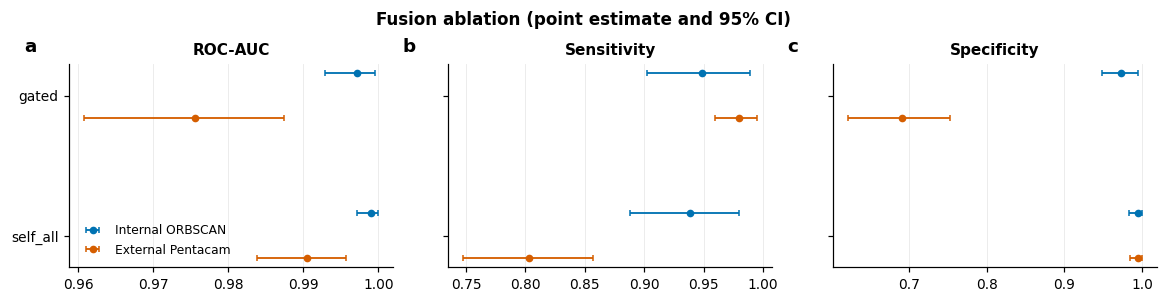

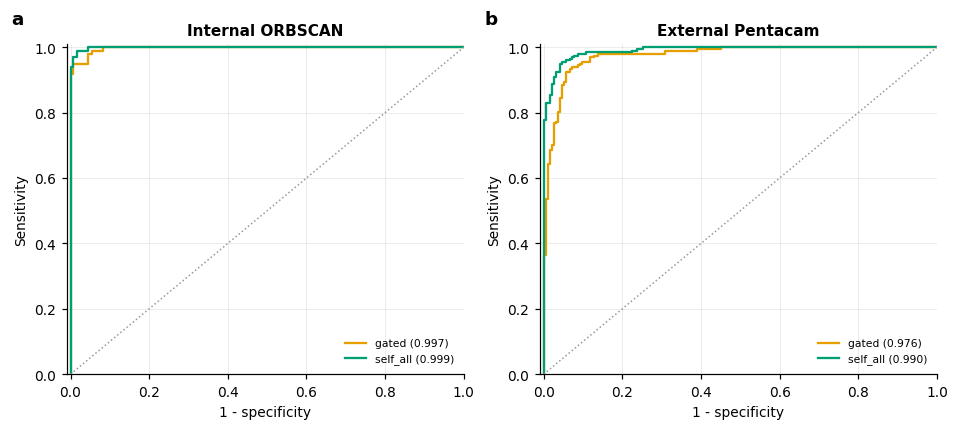

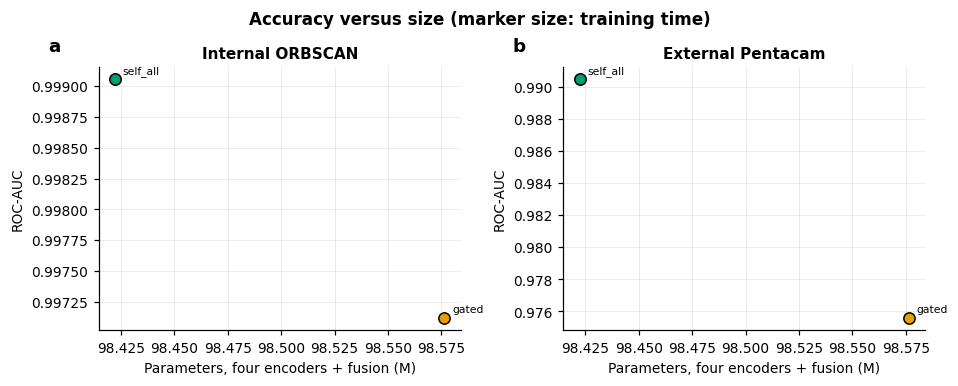

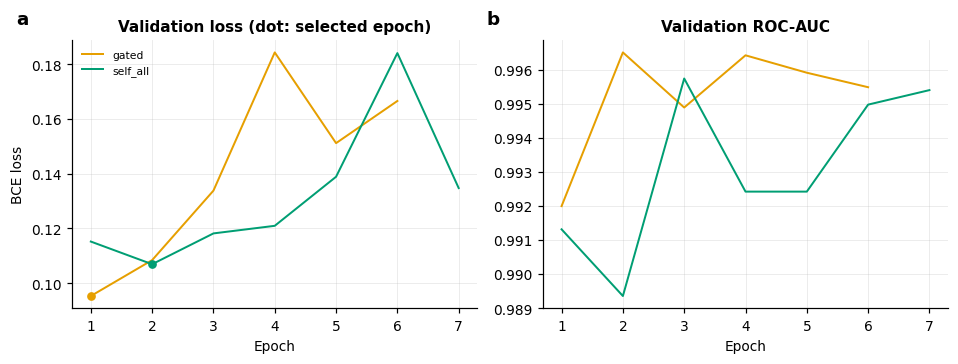

In [8]:
palette = dict(zip(order, ['#E69F00', '#009E73'][:len(order)]))
panels = [('roc_auc', 'ROC-AUC'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity')]

fig, ax = plt.subplots(1, 3, figsize=(10.5, 0.52 * len(order) + 1.6), sharey=True)
for a, (m, title) in zip(ax, panels):
    for k, (cohort, colour, off) in enumerate((('Internal ORBSCAN', C_INT, -.16), ('External Pentacam', C_EXT, .16))):
        d = numeric[(numeric.cohort == cohort) & (numeric.metric == m)].set_index('variant').loc[order]
        yy = np.arange(len(order)) + off
        a.errorbar(d.value, yy, xerr=[d.value - d.ci_low, d.ci_high - d.value], fmt='o', ms=4, color=colour,
                   elinewidth=1.2, capsize=2, label=cohort)
    a.set_title(title); a.set_yticks(range(len(order))); a.set_yticklabels(order); a.invert_yaxis()
    a.grid(axis='y', visible=False)
ax[0].legend(loc='lower left')
for a, l in zip(ax, 'abc'):
    tag(a, l)
fig.suptitle('Fusion ablation (point estimate and 95% CI)', fontsize=11, fontweight='bold')
save(fig, 'fig_ablation_forest')

fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.8))
for a, (cohort, key), l in zip(ax, (('Internal ORBSCAN', 'internal'), ('External Pentacam', 'external')), 'ab'):
    for n in order:
        yt, yp = results[n][key]
        fpr, tpr, _ = roc_curve(yt, yp)
        a.plot(fpr, tpr, color=palette[n], lw=1.5,
               label=f'{n} ({roc_auc_score(yt, yp):.3f})')
    a.plot([0, 1], [0, 1], color='#999', ls=':', lw=1)
    a.set(title=cohort, xlabel='1 - specificity', ylabel='Sensitivity', xlim=(-.01, 1), ylim=(0, 1.01))
    a.legend(loc='lower right', fontsize=7)
    tag(a, l)
save(fig, 'fig_ablation_roc')

fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.4))
for a, (cohort, l) in zip(ax, (('Internal ORBSCAN', 'a'), ('External Pentacam', 'b'))):
    d = numeric[(numeric.cohort == cohort) & (numeric.metric == 'roc_auc')].set_index('variant').loc[order]
    for n in order:
        a.scatter(cost.params_M[n], d.value[n], s=45 + 0.12 * cost.train_minutes[n] * 5, color=palette[n],
                  edgecolor='k', zorder=3)
        a.annotate(n, (cost.params_M[n], d.value[n]), xytext=(5, 4), textcoords='offset points', fontsize=7)
    a.set(title=cohort, xlabel='Parameters, four encoders + fusion (M)', ylabel='ROC-AUC')
    tag(a, l)
fig.suptitle('Accuracy versus size (marker size: training time)', fontsize=11, fontweight='bold')
save(fig, 'fig_ablation_size_vs_auc')

fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.2))
for n in order:
    h = results[n]['history']
    if h.empty:
        continue
    ax[0].plot(h.epoch, h.val_loss, color=palette[n], lw=1.3, label=n)
    ax[0].scatter([results[n]['info']['best_epoch']],
                  [h.val_loss[h.epoch == results[n]['info']['best_epoch']].iloc[0]], color=palette[n], s=22, zorder=3)
    ax[1].plot(h.epoch, h.val_auc, color=palette[n], lw=1.3)
ax[0].set(title='Validation loss (dot: selected epoch)', xlabel='Epoch', ylabel='BCE loss')
ax[1].set(title='Validation ROC-AUC', xlabel='Epoch')
ax[0].legend(fontsize=7)
tag(ax[0], 'a'); tag(ax[1], 'b')
save(fig, 'fig_ablation_training')

In [9]:
with open(ABL_DIR / 'README.txt', 'w') as f:
    f.write('Fusion ablation (ResNet-50 encoders): cross-modal attention fusion, keratoconus (ORBSCAN -> Pentacam zero-shot)\n\n')
    f.write(f'Variants: {", ".join(order)}\n')
    if failed:
        f.write(f'Failed: {failed}\n')
    f.write(f'Seed {SEED}, image size {IMG_SIZE}, batch {BATCH_SIZE}, max epochs {EPOCHS}, '
            f'selection by {SELECT_BY}, EMA {EMA_DECAY}, sensitivity floor {MIN_SENSITIVITY}, rule {THRESHOLD_RULE}\n')
    f.write(f'torch {torch.__version__}, GPU {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"}, '
            f'python {platform.python_version()}\n\n')
    f.write('SHA-256 of the evaluated weights of each run (weights themselves are not included):\n')
    for n in order:
        f.write(f"  {n}: {results[n]['info']['sha256']}\n")
    f.write('\nFiles: ablation_*.csv (tables), <variant>/ (history, predictions, run summary), '
            'train/validation/test_split.csv (patient-grouped splits), figures/ (png + pdf).\n')

zip_path = WORK / 'fusion_ablation_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(ABL_DIR.rglob('*')):
        if f.is_file() and f.suffix != '.pt':
            z.write(f, arcname=str(f.relative_to(ABL_DIR)))
    for f in sorted(FIG_DIR.glob('*')):
        z.write(f, arcname=f'figures/{f.name}')
    for n in ('train', 'validation', 'test'):
        z.write(WORK / f'{n}_split.csv', arcname=f'{n}_split.csv')
with zipfile.ZipFile(zip_path) as z:
    names = z.namelist()
print(f'{len(names)} files, {zip_path.stat().st_size / 1e6:.1f} MB -> {zip_path}')
for n_ in names:
    print(' ', n_)

27 files, 0.6 MB -> /kaggle/working/fusion_ablation_results.zip
  README.txt
  ablation_cost_and_operating_points.csv
  ablation_external_table.csv
  ablation_internal_table.csv
  ablation_metrics_numeric.csv
  gated/external_pentacam_predictions.csv
  gated/run_summary.json
  gated/test_predictions.csv
  gated/training_history.csv
  self_all/external_pentacam_predictions.csv
  self_all/run_summary.json
  self_all/test_predictions.csv
  self_all/training_history.csv
  worker.py
  worker_gpu1.log
  worker_results.pkl
  figures/fig_ablation_forest.pdf
  figures/fig_ablation_forest.png
  figures/fig_ablation_roc.pdf
  figures/fig_ablation_roc.png
  figures/fig_ablation_size_vs_auc.pdf
  figures/fig_ablation_size_vs_auc.png
  figures/fig_ablation_training.pdf
  figures/fig_ablation_training.png
  train_split.csv
  validation_split.csv
  test_split.csv
